# 04 · Expression — EMT transcription factors on the trajectory

For the non-branching path the expression step follows signatures directly (there is no
correlation/module step — those are branching-only). We ask which EMT-TFs are expressed on
the pSom→Crest axis and where they sit. The result is **negative in an informative way**:
the only two canonical EMT-TFs above the detection floor — **FOXC1 and TWIST1** — are both
enriched at the Somitogenesis-high **root** and decline toward the neural-crest terminus
(ρ=−0.09 / −0.06); canonical drivers SNAI1/ZEB1 sit at the floor (3.0% / 0.4%). **No
canonical EMT-TF is induced at the terminus** — the neural-crest terminal state is defined
by the Crest program, not by EMT-TF induction. The panel below matches the reference EMT-TF
style: thresholded expressers overlaid on the grey manifold.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())

### Screen the EMT-TF panel — expression and direction
Rank the canonical EMT-TF panel by expressed fraction; classify each as a **root** or
**terminus** marker only if its expression actually rises in that direction (Spearman ρ sign
plus early/late mean comparison — the honest direction test). Keep those expressed in > 3%
of cells.

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    pole = 'terminus' if (rho > 0 and x[late].mean() > x[early].mean()) else 'root'
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3), pole))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t','pole']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
expr = df[df.frac_expr > 0.03]
n_term = int((expr.pole == 'terminus').sum())
print(f'\nexpressed canonical EMT-TFs (>3%): {list(expr.TF)}')
print(f'of these, {n_term} rise toward the neural-crest terminus; {len(expr)-n_term} are root-enriched (decline)')
tf_show = list(expr.sort_values("frac_expr", ascending=False).TF)[:2]   # two most-expressed for display
print('displayed EMT-TFs:', tf_show, '(both root-enriched; SNAI1/ZEB1 at the detection floor)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t pole
TWIST1      0.076       0.041      0.021    -0.064 root
 FOXC1      0.066       0.034      0.015    -0.095 root
 SNAI1      0.030       0.011      0.007    -0.025 root
 SNAI2      0.006       0.004      0.001    -0.039 root
  ZEB2      0.006       0.003      0.001    -0.023 root
  ZEB1      0.004       0.002      0.001    -0.016 root
 PRRX2      0.001       0.000      0.000    -0.011 root
 PRRX1      0.001       0.001      0.000    -0.001 root
TWIST2      0.000       0.000      0.000    -0.003 root
 FOXC2      0.000       0.000      0.000     0.001 root

expressed canonical EMT-TFs (>3%): ['TWIST1', 'FOXC1']
of these, 0 rise toward the neural-crest terminus; 2 are root-enriched (decline)
displayed EMT-TFs: ['TWIST1', 'FOXC1'] (both root-enriched; SNAI1/ZEB1 at the detection floor)


### EMT-TF spatial overlay (deliverable)
`expression.pdf`: reference EMT-TF style — the grey manifold with thresholded expressers of
the two expressed canonical EMT-TFs overlaid, on the oriented (pseudotime left→right) panel.
Both concentrate at the Somitogenesis root (left); the neural-crest terminus (right) carries
no canonical EMT-TF, the informative negative result.

saved expression.pdf | overlay ['TWIST1', 'FOXC1'] (both root-enriched)


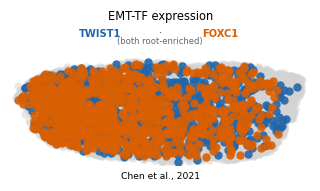

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def expr_vec(g):
    v = adata[:,g].X
    return np.asarray(v.todense()).ravel() if hasattr(v,'todense') else np.asarray(v).ravel()
cols = {tf_show[0]:'#2166ac', tf_show[1]:'#d95f02'}   # two distinct hues
fig, ax = plt.subplots(figsize=(3.5,1.5))
ax.scatter(xl[:,0], xl[:,1], s=30, color='lightgrey', alpha=.5, linewidths=0, rasterized=True)
for g in tf_show:
    m = expr_vec(g) > 0
    ax.scatter(xl[m,0], xl[m,1], s=30, color=cols[g], alpha=.9, linewidths=0, rasterized=True)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py, yhi+py + (yhi-ylo)*.20); ax.axis('off')
# reference-style single header line: coloured TF names inline, no boxed legend
xmid = (xlo+xhi)/2; ytop = yhi + (yhi-ylo)*.13
ax.text(.5, 1.15, 'EMT-TF expression', ha='center', transform=ax.transAxes, size=7.5)
ax.text(.30, 1.02, tf_show[0], ha='center', transform=ax.transAxes, size=6.5, color=cols[tf_show[0]], weight='bold')
ax.text(.50, 1.02, '·', ha='center', transform=ax.transAxes, size=6.5, color='0.3')
ax.text(.70, 1.02, tf_show[1], ha='center', transform=ax.transAxes, size=6.5, color=cols[tf_show[1]], weight='bold')
ax.text(.5, .96, '(both root-enriched)', ha='center', transform=ax.transAxes, size=5.5, color='0.4')
ax.text(.5,-.10,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf | overlay', tf_show, '(both root-enriched)')